<a href="https://colab.research.google.com/github/ISSENY/AF3/blob/main/AF3_Simulaci%C3%B3n_num%C3%A9rica_e_interpretaci%C3%B3n_del_comportamiento_din%C3%A1mico.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

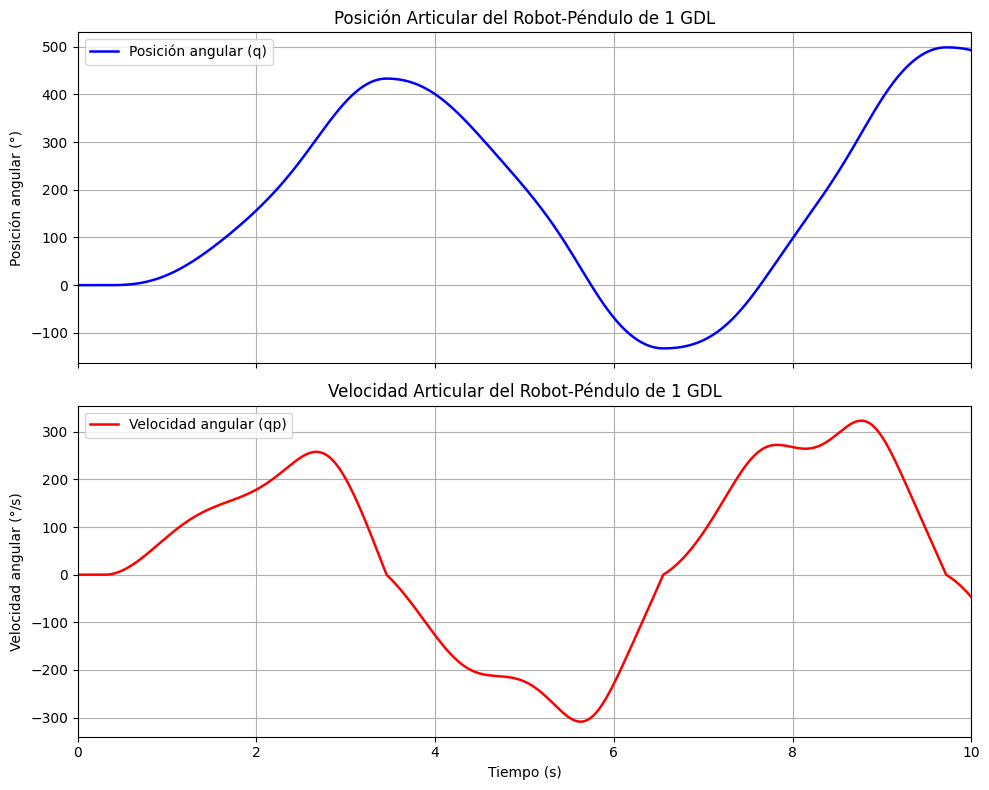

 SIMULACIÓN DEL ROBOT-PÉNDULO DE 1 GDL

PARÁMETROS DEL SISTEMA
Momento de inercia: 0.16 kg*m^2
Masa: 5.0 kg
Gravedad: 9.81 m/s^2
Centro de masa: 0.01 m
Fricción viscosa: 0.14 N*m*s/rad
Fricción de Coulomb: 0.45 N*m

CONDICIONES INICIALES
Posición inicial: 0.0 rad
Velocidad inicial: 0.0 rad/s

DATOS DE SIMULACIÓN
Tiempo inicial: 0.0 s
Tiempo final: 10.0 s
Intervalo de muestreo: 0.0025 s

RESULTADOS FINALES
Posición final: 8.599778 rad
Posición final: 492.730974 grados
Velocidad final: -0.816145 rad/s
Velocidad final: -46.761677 grados/s

Simulación completada correctamente.


In [ ]:

# ================================================================
# AF3 - Simulación numérica e interpretación del comportamiento dinámico
# ================================================================
# Simulación del comportamiento dinámico de un robot-péndulo
# mediante la solución numérica de ecuaciones diferenciales.

import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

# ================================================================
# 1. PARÁMETROS DEL SISTEMA
# ================================================================

Ir = 0.16      # Momento de inercia (kg*m^2)
m = 5.0        # Masa del mecanismo (kg)
g = 9.81       # Aceleración de la gravedad (m/s^2)
lc = 0.01      # Distancia al centro de masa (m)
b = 0.14       # Coeficiente de fricción viscosa (N*m*s/rad)
fc = 0.45      # Coeficiente de fricción de Coulomb (N*m)


# ================================================================
# 2. TORQUE DE ENTRADA DEL MOTOR
# ================================================================

def tau(t):
    # Torque sinusoidal de amplitud 1.5 N*m
    return 1.5 * np.sin(t)


# ================================================================
# 3. ECUACIÓN DINÁMICA DEL ROBOT-PÉNDULO
#    Equivalente a f.m de MATLAB
# ================================================================

def f(t, x):

    # Variables de estado
    q = x[0]       # Posición angular (rad)
    qp = x[1]      # Velocidad angular (rad/s)

    # Torque aplicado por el motor
    tau_motor = tau(t)

    # Fricción de Coulomb
    # Aproximación continua de la función signo
    friccion_coulomb = fc * np.tanh(100000 * qp)

    # Ecuación dinámica del péndulo
    # Ir*qpp + b*qp + fc*sign(qp) + m*g*lc*sin(q) = tau

    # Despeje de la aceleración angular
    qpp = (
        tau_motor
        - m * g * lc * np.sin(q)
        - b * qp
        - friccion_coulomb
    ) / Ir

    # Representación en espacio de estados
    # x1 = q
    # x2 = qp
    # dx1/dt = x2
    # dx2/dt = qpp

    dxdt = [qp, qpp]

    return dxdt


# ================================================================
# 4. SCRIPT PRINCIPAL DE SIMULACIÓN
#    Equivalente a ResPS.m de MATLAB
# ================================================================

# Parámetros de simulación
ti = 0.0        # Tiempo inicial (s)
tf = 10.0       # Tiempo final (s)
h = 0.0025      # Intervalo de muestreo (s)

# Vector de tiempo
ts = np.arange(ti, tf + h/2, h)


# ================================================================
# 5. CONDICIONES INICIALES
# ================================================================

# Condiciones establecidas en la actividad:
# X1 = 0
# X2 = 0

q0 = 0.0        # Posición inicial (rad)
qp0 = 0.0       # Velocidad inicial (rad/s)

# Vector de condiciones iniciales
x0 = [q0, qp0]


# ================================================================
# 6. SOLUCIÓN NUMÉRICA DE LA ECUACIÓN DIFERENCIAL
# ================================================================

# Se utiliza solve_ivp con el método RK45,
# equivalente en propósito a ode45 de MATLAB.

sol = solve_ivp(
    fun=f,
    t_span=(ti, tf),
    y0=x0,
    method='RK45',
    t_eval=ts,
    rtol=1e-8,
    atol=1e-10,
    max_step=0.0025
)

# Verificar que la solución se haya obtenido correctamente
if not sol.success:
    raise RuntimeError(
        "Error durante la simulación: " + sol.message
    )

# Extraer los resultados
t = sol.t

# Cada fila de sol.y corresponde a un estado
posicion = sol.y[0]     # Posición angular (rad)
velocidad = sol.y[1]    # Velocidad angular (rad/s)


# ================================================================
# 7. CONVERSIÓN DE RADIANES A GRADOS
# ================================================================

# Convertir la posición de radianes a grados
posicion_grados = np.rad2deg(posicion)

# Convertir la velocidad de rad/s a grados/s
velocidad_grados = np.rad2deg(velocidad)


# ================================================================
# 8. GRÁFICAS DE POSICIÓN Y VELOCIDAD ARTICULAR
# ================================================================

# Crear figura con dos gráficas
fig, (ax1, ax2) = plt.subplots(
    2, 1,
    figsize=(10, 8),
    sharex=True
)

# ------------------------------------------------
# GRÁFICA 1: POSICIÓN ARTICULAR
# ------------------------------------------------

ax1.plot(
    t,
    posicion_grados,
    'b-',
    linewidth=1.8,
    label='Posición angular (q)'
)

ax1.set_title(
    'Posición Articular del Robot-Péndulo de 1 GDL'
)

ax1.set_ylabel('Posición angular (°)')
ax1.grid(True)
ax1.legend()


# ------------------------------------------------
# GRÁFICA 2: VELOCIDAD ARTICULAR
# ------------------------------------------------

ax2.plot(
    t,
    velocidad_grados,
    'r-',
    linewidth=1.8,
    label='Velocidad angular (qp)'
)

ax2.set_title(
    'Velocidad Articular del Robot-Péndulo de 1 GDL'
)

ax2.set_xlabel('Tiempo (s)')
ax2.set_ylabel('Velocidad angular (°/s)')
ax2.grid(True)
ax2.legend()

# Limitar el eje horizontal a 10 segundos
ax2.set_xlim(ti, tf)

# Ajustar separación entre gráficas
plt.tight_layout()

# Mostrar las gráficas
plt.show()


# ================================================================
# 9. PRESENTACIÓN DE RESULTADOS
# ================================================================

print("==============================================")
print(" SIMULACIÓN DEL ROBOT-PÉNDULO DE 1 GDL")
print("==============================================")

print("\nPARÁMETROS DEL SISTEMA")
print(f"Momento de inercia: {Ir} kg*m^2")
print(f"Masa: {m} kg")
print(f"Gravedad: {g} m/s^2")
print(f"Centro de masa: {lc} m")
print(f"Fricción viscosa: {b} N*m*s/rad")
print(f"Fricción de Coulomb: {fc} N*m")

print("\nCONDICIONES INICIALES")
print(f"Posición inicial: {q0} rad")
print(f"Velocidad inicial: {qp0} rad/s")

print("\nDATOS DE SIMULACIÓN")
print(f"Tiempo inicial: {ti} s")
print(f"Tiempo final: {tf} s")
print(f"Intervalo de muestreo: {h} s")

print("\nRESULTADOS FINALES")
print(f"Posición final: {posicion[-1]:.6f} rad")
print(f"Posición final: {posicion_grados[-1]:.6f} grados")
print(f"Velocidad final: {velocidad[-1]:.6f} rad/s")
print(f"Velocidad final: {velocidad_grados[-1]:.6f} grados/s")

print("\nSimulación completada correctamente.")
print("==============================================")
